<a href="https://colab.research.google.com/github/RiyaSunil28/nitinternship/blob/main/Week5_nit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q open_clip_torch ftfy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 38.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.6 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import open_clip

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import product

from torchvision import datasets
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import roc_auc_score, roc_curve

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

Using device: cuda


In [ ]:
model, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="openai"
)

tokenizer = open_clip.get_tokenizer("ViT-B-32")

model = model.to(device)
model.eval()

for param in model.parameters():
    param.requires_grad = False

print("CLIP loaded and frozen")

open_clip_model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


CLIP loaded and frozen


In [ ]:
!rm -f data/cifar-10-python.tar.gz data/cifar-100-python.tar.gz
!wget https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz -P data
!wget https://data.brainchip.com/dataset-mirror/cifar100/cifar-100-python.tar.gz -P data
!ls -lh data

--2026-07-15 12:55:20--  https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz
Resolving data.brainchip.com (data.brainchip.com)... 146.59.209.152, 2001:41d0:301::31
Connecting to data.brainchip.com (data.brainchip.com)|146.59.209.152|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 170498071 (163M) [application/x-gzip]
Saving to: ‘data/cifar-10-python.tar.gz’

cifar-10-python.tar 100%[===================>] 162.60M  4.46MB/s    in 40s     

2026-07-15 12:56:00 (4.12 MB/s) - ‘data/cifar-10-python.tar.gz’ saved [170498071/170498071]

--2026-07-15 12:56:00--  https://data.brainchip.com/dataset-mirror/cifar100/cifar-100-python.tar.gz
Resolving data.brainchip.com (data.brainchip.com)... 146.59.209.152, 2001:41d0:301::31
Connecting to data.brainchip.com (data.brainchip.com)|146.59.209.152|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 169001437 (161M) [application/x-gzip]
Saving to: ‘data/cifar-100-python.tar.gz’

cifar-1

In [ ]:
train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=preprocess
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=preprocess
)

cifar100_test = datasets.CIFAR100(
    root="./data",
    train=False,
    download=True,
    transform=preprocess
)

In [ ]:
class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

known_classes = [0, 1, 3, 5, 7]
unknown_classes = [2, 4, 6, 8, 9]

known_names = [class_names[i] for i in known_classes]

print("Known classes:", known_names)

Known classes: ['airplane', 'automobile', 'cat', 'dog', 'horse']


In [ ]:
known_train_indices = [
    i for i, label in enumerate(train_dataset.targets)
    if label in known_classes
]

known_test_indices = [
    i for i, label in enumerate(test_dataset.targets)
    if label in known_classes
]

unknown_test_indices = [
    i for i, label in enumerate(test_dataset.targets)
    if label in unknown_classes
]

print("Known train samples:", len(known_train_indices))
print("Known test samples:", len(known_test_indices))
print("Unknown test samples:", len(unknown_test_indices))

Known train samples: 25000
Known test samples: 5000
Unknown test samples: 5000


In [ ]:
def extract_features(dataset, indices=None):

    if indices is not None:
        dataset = Subset(dataset, indices)

    loader = DataLoader(
        dataset,
        batch_size=256,
        shuffle=False,
        num_workers=2
    )

    all_features = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            image_features = model.encode_image(images)

            image_features = image_features / image_features.norm(
                dim=-1,
                keepdim=True
            )

            all_features.append(image_features.cpu())
            all_labels.append(labels)

    return torch.cat(all_features), torch.cat(all_labels)

In [ ]:
known_train_features, known_train_labels = extract_features(
    train_dataset,
    known_train_indices
)

known_test_features, _ = extract_features(
    test_dataset,
    known_test_indices
)

unknown_test_features, _ = extract_features(
    test_dataset,
    unknown_test_indices
)

print("Known train features:", known_train_features.shape)
print("Known test features:", known_test_features.shape)
print("Unknown test features:", unknown_test_features.shape)

Known train features: torch.Size([25000, 512])
Known test features: torch.Size([5000, 512])
Unknown test features: torch.Size([5000, 512])


In [ ]:
val_unknown_features, _ = extract_features(
    cifar100_test,
    list(range(5000))
)

print("Validation unknown features:", val_unknown_features.shape)

Validation unknown features: torch.Size([5000, 512])


In [ ]:
generator = torch.Generator().manual_seed(42)

perm = torch.randperm(
    known_train_features.shape[0],
    generator=generator
)

split = int(0.8 * len(perm))

fit_idx = perm[:split]
val_idx = perm[split:]

fit_features = known_train_features[fit_idx]
fit_labels = known_train_labels[fit_idx]

val_known_features = known_train_features[val_idx]

print("Prompt training samples:", fit_features.shape[0])
print("Validation known samples:", val_known_features.shape[0])

Prompt training samples: 20000
Validation known samples: 5000


In [ ]:
fit_targets = torch.tensor([
    known_classes.index(int(label))
    for label in fit_labels
])

print("Remapped targets:", fit_targets[:10])

Remapped targets: tensor([0, 3, 4, 2, 3, 3, 1, 2, 0, 2])


In [ ]:
prompts = [
    f"a photo of a {name}"
    for name in known_names
]

text_tokens = tokenizer(prompts).to(device)

with torch.no_grad():

    text_features = model.encode_text(text_tokens)

    text_features = text_features / text_features.norm(
        dim=-1,
        keepdim=True
    )

print(prompts)

['a photo of a airplane', 'a photo of a automobile', 'a photo of a cat', 'a photo of a dog', 'a photo of a horse']


In [ ]:
feature_dim = text_features.shape[1]

prompt_vectors = nn.Parameter(
    torch.randn(
        len(known_classes),
        feature_dim,
        device=device
    ) * 0.01
)

optimizer = optim.Adam(
    [prompt_vectors],
    lr=1e-3
)

criterion = nn.CrossEntropyLoss()

logit_scale = model.logit_scale.exp().detach()

print("Prompt vectors:", prompt_vectors.shape)
print("Logit scale:", logit_scale.item())

Prompt vectors: torch.Size([5, 512])
Logit scale: 100.0


In [ ]:
epochs = 10
batch_size = 512

fit_features_device = fit_features.to(device)
fit_targets_device = fit_targets.to(device)

loss_history = []

for epoch in range(epochs):

    epoch_perm = torch.randperm(fit_features_device.shape[0])

    epoch_loss = 0
    num_batches = 0

    for start in range(0, len(epoch_perm), batch_size):

        batch_idx = epoch_perm[start:start + batch_size]

        image_features = fit_features_device[batch_idx]
        targets = fit_targets_device[batch_idx]

        adapted_text = text_features + prompt_vectors

        adapted_text = adapted_text / adapted_text.norm(
            dim=-1,
            keepdim=True
        )

        logits = logit_scale * image_features @ adapted_text.T

        loss = criterion(logits, targets)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        epoch_loss += loss.item()
        num_batches += 1

    avg_loss = epoch_loss / num_batches

    loss_history.append(avg_loss)

    print(f"Epoch {epoch+1}/{epochs} - Loss: {avg_loss:.4f}")

Epoch 1/10 - Loss: 0.1301
Epoch 2/10 - Loss: 0.1013
Epoch 3/10 - Loss: 0.0952
Epoch 4/10 - Loss: 0.0874
Epoch 5/10 - Loss: 0.0858
Epoch 6/10 - Loss: 0.0832
Epoch 7/10 - Loss: 0.0823
Epoch 8/10 - Loss: 0.0805
Epoch 9/10 - Loss: 0.0795
Epoch 10/10 - Loss: 0.0790


In [ ]:
with torch.no_grad():

    tuned_text = text_features + prompt_vectors

    tuned_text = tuned_text / tuned_text.norm(
        dim=-1,
        keepdim=True
    )

print("Tuned text features:", tuned_text.shape)

Tuned text features: torch.Size([5, 512])


In [ ]:
centroids = []

for class_idx in range(len(known_classes)):

    class_features = fit_features[fit_targets == class_idx]

    centroid = class_features.mean(dim=0)

    centroid = centroid / centroid.norm()

    centroids.append(centroid)

centroids = torch.stack(centroids).to(device)

print("Centroids:", centroids.shape)

Centroids: torch.Size([5, 512])


In [ ]:
def compute_scores(image_features):

    image_features = image_features.to(device)

    with torch.no_grad():

        similarities = image_features @ tuned_text.T

        logits = logit_scale * similarities

        energy = torch.logsumexp(logits, dim=1)

        top2 = similarities.topk(2, dim=1).values

        margin = top2[:, 0] - top2[:, 1]

        centroid_similarity = (
            image_features @ centroids.T
        ).max(dim=1).values

    return (
        energy.cpu().numpy(),
        margin.cpu().numpy(),
        centroid_similarity.cpu().numpy()
    )

In [ ]:
val_known_scores = compute_scores(val_known_features)
val_unknown_scores = compute_scores(val_unknown_features)

test_known_scores = compute_scores(known_test_features)
test_unknown_scores = compute_scores(unknown_test_features)

print("Scores computed for all splits")

Scores computed for all splits


In [ ]:
means = [scores.mean() for scores in val_known_scores]
stds = [scores.std() for scores in val_known_scores]

def normalize(score_tuple):
    return [
        (score_tuple[i] - means[i]) / stds[i]
        for i in range(3)
    ]

val_known_norm = normalize(val_known_scores)
val_unknown_norm = normalize(val_unknown_scores)

test_known_norm = normalize(test_known_scores)
test_unknown_norm = normalize(test_unknown_scores)

In [ ]:
def fused_auroc(known_norm, unknown_norm, weights):

    a, b, c = weights

    known_fused = (
        a * known_norm[0]
        + b * known_norm[1]
        + c * known_norm[2]
    )

    unknown_fused = (
        a * unknown_norm[0]
        + b * unknown_norm[1]
        + c * unknown_norm[2]
    )

    labels = np.concatenate([
        np.ones(len(known_fused)),
        np.zeros(len(unknown_fused))
    ])

    scores = np.concatenate([
        known_fused,
        unknown_fused
    ])

    return roc_auc_score(labels, scores)

In [ ]:
weight_values = [0.0, 0.25, 0.5, 0.75, 1.0]

best_weights = None
best_val_auroc = 0

for a, b, c in product(weight_values, repeat=3):

    if a + b + c == 0:
        continue

    total = a + b + c

    weights = (a / total, b / total, c / total)

    auroc = fused_auroc(
        val_known_norm,
        val_unknown_norm,
        weights
    )

    if auroc > best_val_auroc:
        best_val_auroc = auroc
        best_weights = weights

print("Best weights (a, b, c):",
      tuple(round(w, 3) for w in best_weights))

print("Validation AUROC:", round(best_val_auroc, 4))

Best weights (a, b, c): (0.5, 0.25, 0.25)
Validation AUROC: 0.962


In [ ]:
ablation_settings = [
    ("Energy only", (1, 0, 0)),
    ("Margin only", (0, 1, 0)),
    ("Distance only", (0, 0, 1)),
    ("Energy + Margin", (0.5, 0.5, 0)),
    ("Energy + Distance", (0.5, 0, 0.5)),
    ("Margin + Distance", (0, 0.5, 0.5)),
    ("Fused (tuned weights)", best_weights)
]

ablation_results = []

for name, weights in ablation_settings:

    auroc = fused_auroc(
        test_known_norm,
        test_unknown_norm,
        weights
    )

    ablation_results.append({
        "Method": name,
        "AUROC": round(auroc, 4)
    })

results = pd.DataFrame(ablation_results)

results

,Method,AUROC
0,Energy only,0.9253
1,Margin only,0.8626
2,Distance only,0.8697
3,Energy + Margin,0.9103
4,Energy + Distance,0.9455
5,Margin + Distance,0.9356
6,Fused (tuned weights),0.9447


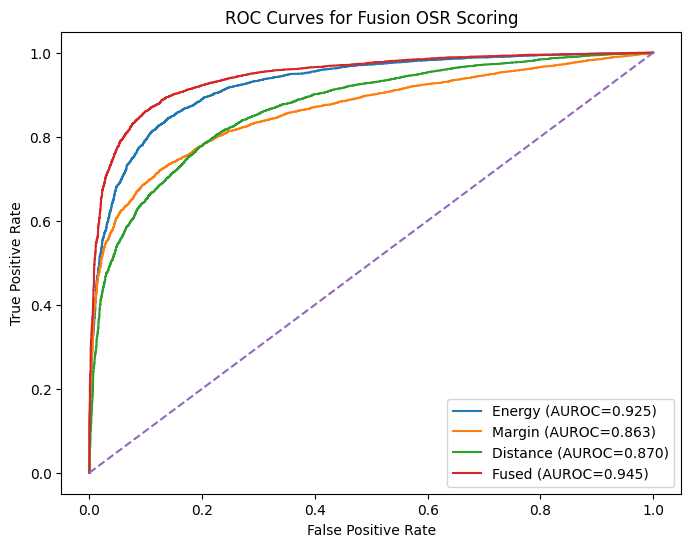

In [ ]:
def fused_scores(known_norm, unknown_norm, weights):

    a, b, c = weights

    known = (
        a * known_norm[0]
        + b * known_norm[1]
        + c * known_norm[2]
    )

    unknown = (
        a * unknown_norm[0]
        + b * unknown_norm[1]
        + c * unknown_norm[2]
    )

    labels = np.concatenate([
        np.ones(len(known)),
        np.zeros(len(unknown))
    ])

    return labels, np.concatenate([known, unknown])

plt.figure(figsize=(8, 6))

for name, weights in [
    ("Energy", (1, 0, 0)),
    ("Margin", (0, 1, 0)),
    ("Distance", (0, 0, 1)),
    ("Fused", best_weights)
]:

    labels, scores = fused_scores(
        test_known_norm,
        test_unknown_norm,
        weights
    )

    fpr, tpr, _ = roc_curve(labels, scores)

    auroc = roc_auc_score(labels, scores)

    plt.plot(fpr, tpr, label=f"{name} (AUROC={auroc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curves for Fusion OSR Scoring")

plt.legend()

plt.show()

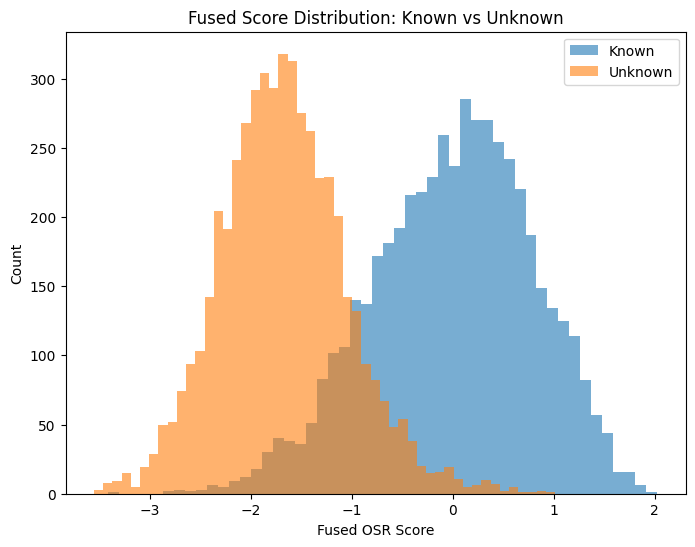

In [ ]:
labels, scores = fused_scores(
    test_known_norm,
    test_unknown_norm,
    best_weights
)

known_fused = scores[labels == 1]
unknown_fused = scores[labels == 0]

plt.figure(figsize=(8, 6))

plt.hist(known_fused, bins=50, alpha=0.6, label="Known")
plt.hist(unknown_fused, bins=50, alpha=0.6, label="Unknown")

plt.xlabel("Fused OSR Score")
plt.ylabel("Count")

plt.title("Fused Score Distribution: Known vs Unknown")

plt.legend()

plt.show()

In [ ]:
results.to_csv("week5_ablation_results.csv", index=False)

print("Saved: week5_ablation_results.csv")

Saved: week5_ablation_results.csv
